# EDA A5 – Gdzie tracimy pieniądze?

Pytanie biznesowe: **ile przychodu tracimy na anulowaniach i zwrotach i czy straty koncentrują się
w konkretnych kategoriach, markach, krajach lub segmentach klientów?**

Dlaczego to ważne dla reklamy: kampania płaci za kliknięcie / zamówienie, ale anulowane i zwrócone zamówienia
nie przynoszą przychodu. Jeśli jakiś segment ma wyraźnie wyższy odsetek zwrotów, jego **prawdziwy ROAS jest niższy**,
niż pokazuje liczba złożonych zamówień.

Definicje (z `CLAUDE.md`):
* **cancel rate** = % zamówień ze statusem Cancelled, **return rate** = % zamówień ze statusem Returned
  (mianownik: wszystkie zamówienia),
* **utracona wartość** = wartość zamówień Cancelled + Returned,
* status bierzemy z `orders` (A1).

## Wczytanie danych

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

from bq_utils import read_bq
from viz_style import apply_style, legend_outside, COLORS

apply_style()

REVENUE_STATUSES = ["Complete", "Shipped"]
LOST_STATUSES = ["Cancelled", "Returned"]

In [2]:
# Orders – status and customer gender

orders = read_bq("orders", usecols=["order_id", "user_id", "status", "gender"],
                 dtype={"order_id": "Int32", "user_id": "Int32", "status": "category",
                        "gender": "category"})

orders.head()

Zapytanie przetworzy: 3.64 MB


,order_id,user_id,status,gender
0,6,4,Cancelled,F
1,8,5,Cancelled,F
2,38,28,Cancelled,F
3,52,37,Cancelled,F
4,55,41,Cancelled,F


In [3]:
# Order items – item status loaded only to compare it with the order status

order_items = read_bq("order_items", usecols=["order_id", "product_id", "status", "sale_price"],
                      dtype={"order_id": "Int32", "product_id": "Int32", "status": "category"})

order_items.head()

Zapytanie przetworzy: 6.19 MB


,order_id,product_id,status,sale_price
0,2526,14235,Complete,0.02
1,18153,14235,Processing,0.02
2,47981,14235,Processing,0.02
3,84256,14235,Processing,0.02
4,348,14235,Shipped,0.02


In [4]:
# Products

products = read_bq("products", usecols=["id", "brand", "category", "department", "cost"],
                   dtype={"id": "Int32", "brand": "category", "category": "category",
                          "department": "category"})

products.head()

Zapytanie przetworzy: 1.35 MB


,id,brand,category,department,cost
0,13842,MG,Accessories,Women,2.51875
1,13928,MG,Accessories,Women,2.33835
2,14115,MG,Accessories,Women,4.87956
3,14157,MG,Accessories,Women,4.64877
4,14273,MG,Accessories,Women,6.50793


In [5]:
# Users – country and acquisition channel

users = read_bq("users", usecols=["id", "country", "traffic_source"],
                dtype={"id": "Int32", "country": "category", "traffic_source": "category"})

users.head()

Zapytanie przetworzy: 2.62 MB


,id,country,traffic_source
0,35020,Brasil,Display
1,95787,Brasil,Display
2,99193,Japan,Display
3,26461,United States,Display
4,96153,United States,Display


In [6]:
# Data as of

checked_at = pd.Timestamp.now(tz="UTC")
print(f"Sprawdzono: {checked_at:%Y-%m-%d %H:%M} UTC")

Sprawdzono: 2026-10-29 10:16 UTC


## 0. Kontrola: czy status pozycji zgadza się ze statusem zamówienia?

W A1 przyjęliśmy, że status bierzemy z `orders`. Sprawdzamy, czy `order_items.status` mówi to samo –
jeśli nie, analiza „na poziomie produktu” mogłaby dać inne wyniki niż „na poziomie zamówienia”.

In [7]:
# Agreement between item status and order status

status_check = order_items.merge(orders[["order_id", "status"]], on="order_id",
                                 how="left", suffixes=("_item", "_order"), validate="many_to_one")

agreement = (status_check["status_item"].astype("string") == status_check["status_order"].astype("string")).mean()
print(f"Pozycje ze statusem zgodnym ze statusem zamówienia: {agreement * 100:.2f}%")

pd.crosstab(status_check["status_order"], status_check["status_item"])

Pozycje ze statusem zgodnym ze statusem zamówienia: 100.00%


status_item,Cancelled,Complete,Processing,Returned,Shipped
status_order,,,,,
Cancelled,27077,0,0,0,0
Complete,0,45532,0,0,0
Processing,0,0,35822,0,0
Returned,0,0,0,18039,0
Shipped,0,0,0,0,54276


## Tabele do analizy

* `orders_x` – **jedno zamówienie na wiersz**: wartość, flagi `is_cancelled` / `is_returned`, kraj i kanał klienta.
  Do wymiarów klienta (płeć, kraj, kanał).
* `items_x` – **jedna pozycja na wiersz**: status zamówienia, kategoria, marka, koszt.
  Do wymiarów produktu (kategoria, dział, marka) – zamówienie może zawierać produkty z kilku kategorii.

In [8]:
# Order level

order_value = order_items.groupby("order_id")["sale_price"].sum().rename("order_value")

orders_x = (orders
            .merge(order_value, left_on="order_id", right_index=True, how="left", validate="one_to_one")
            .merge(users, left_on="user_id", right_on="id", how="left", validate="many_to_one")
            .drop(columns="id")
            .fillna({"order_value": 0})
            .assign(is_cancelled=lambda x: x["status"] == "Cancelled",
                    is_returned=lambda x: x["status"] == "Returned",
                    lost_value=lambda x: x["order_value"].where(x["status"].isin(LOST_STATUSES), 0)))

# Item level – status from the order (rule from A1)
items_x = (order_items
           .drop(columns="status")
           .merge(orders[["order_id", "status", "gender"]], on="order_id", how="left", validate="many_to_one")
           .merge(products, left_on="product_id", right_on="id", how="left", validate="many_to_one")
           .drop(columns="id")
           .assign(is_cancelled=lambda x: x["status"] == "Cancelled",
                   is_returned=lambda x: x["status"] == "Returned",
                   lost_value=lambda x: x["sale_price"].where(x["status"].isin(LOST_STATUSES), 0),
                   gross_profit=lambda x: x["sale_price"] - x["cost"]))

print(f"Zamówienia: {len(orders_x):,} (było {len(orders):,}), pozycje: {len(items_x):,} (było {len(order_items):,})")
print(f"Wartość zamówień: {orders_x['order_value'].sum():,.0f} = wartość pozycji: {items_x['sale_price'].sum():,.0f}")

Zamówienia: 124,452 (było 124,452), pozycje: 180,746 (było 180,746)
Wartość zamówień: 10,769,445 = wartość pozycji: 10,769,445


## 1. Skala strat

* Ile zamówień i jaka wartość przypada na każdy status?
* **Z każdych 100 zł zamówień, które się „rozstrzygnęły”** (bez Processing – jeszcze w toku),
  ile zostaje w sklepie, a ile tracimy na anulowaniach i zwrotach?

In [9]:
# Orders and value by status

by_status = (orders_x
             .groupby("status", observed=True)
             .agg(orders=("order_id", "count"), value=("order_value", "sum"))
             .assign(orders_pct=lambda x: x["orders"] / x["orders"].sum() * 100,
                     value_pct=lambda x: x["value"] / x["value"].sum() * 100)
             .sort_values("value", ascending=False))

kept = by_status.loc[REVENUE_STATUSES, "value"].sum()
lost = by_status.loc[LOST_STATUSES, "value"].sum()

print(f"Utracona wartość (Cancelled + Returned): {lost:,.0f}")
print(f"Z każdych 100 zł rozstrzygniętych zamówień sklep zatrzymuje {kept / (kept + lost) * 100:.1f} zł")

by_status.round(1)

Utracona wartość (Cancelled + Returned): 2,670,527
Z każdych 100 zł rozstrzygniętych zamówień sklep zatrzymuje 69.0 zł


,orders,value,orders_pct,value_pct
status,,,,
Shipped,37308,3219945.0,30.0,29.9
Complete,31359,2732924.7,25.2,25.4
Processing,24755,2146048.4,19.9,19.9
Cancelled,18634,1629205.8,15.0,15.1
Returned,12396,1041321.0,10.0,9.7


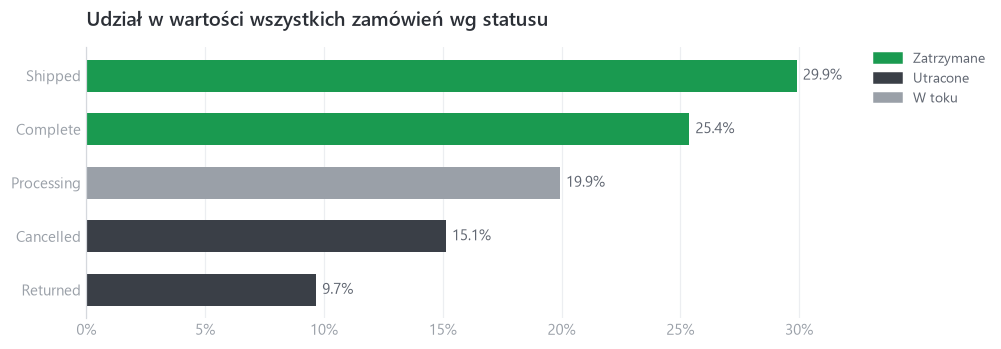

In [10]:
# Chart: share of order value by status – kept vs lost vs still in progress

status_group = {"Complete": "Zatrzymane", "Shipped": "Zatrzymane",
                "Cancelled": "Utracone", "Returned": "Utracone", "Processing": "W toku"}
group_colors = {"Zatrzymane": COLORS["series_1"], "Utracone": COLORS["series_2"], "W toku": COLORS["muted"]}

plot_data = by_status.sort_values("value_pct")
colors = [group_colors[status_group[s]] for s in plot_data.index]

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.barh(plot_data.index.astype(str), plot_data["value_pct"], height=0.6, color=colors)

for i, value in enumerate(plot_data["value_pct"]):
    ax.annotate(f"{value:.1f}%", xy=(value, i), xytext=(4, 0), textcoords="offset points",
                va="center", color=COLORS["text_secondary"])

ax.set_title("Udział w wartości wszystkich zamówień wg statusu")
ax.margins(x=0.08)                                          # room for the value labels
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
ax.spines["left"].set_visible(True)
ax.spines["bottom"].set_visible(False)
legend_outside(ax, handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in group_colors.values()],
               labels=list(group_colors.keys()))
plt.show()

## 2. Czy jakiś wymiar różnicuje anulowania i zwroty?

Funkcja `rate_table()` liczy dla każdej grupy: liczebność, cancel rate, return rate, utraconą wartość
oraz **z-score** – o ile błędów standardowych grupa odbiega od średniej ogólnej.

* |z| > 1,96 oznacza różnicę „istotną” na poziomie 5%.
* **Pułapka wielokrotnych porównań:** przy 26 kategoriach średnio ~1,3 grupy przekroczy ten próg **czysto przypadkiem**.
  Dlatego na końcu porównujemy liczbę „istotnych” grup z liczbą oczekiwaną przy braku jakichkolwiek różnic.

In [11]:
# Rates by group with z-score vs the overall rate

def rate_table(df, by):
    overall_cancel = df["is_cancelled"].mean()
    overall_return = df["is_returned"].mean()

    t = (df.groupby(by, observed=True)
           .agg(n=("is_returned", "size"),
                cancel_rate=("is_cancelled", "mean"),
                return_rate=("is_returned", "mean"),
                lost_value=("lost_value", "sum")))

    t["cancel_z"] = (t["cancel_rate"] - overall_cancel) / np.sqrt(overall_cancel * (1 - overall_cancel) / t["n"])
    t["return_z"] = (t["return_rate"] - overall_return) / np.sqrt(overall_return * (1 - overall_return) / t["n"])
    t["return_ci"] = 1.96 * np.sqrt(t["return_rate"] * (1 - t["return_rate"]) / t["n"])   # 95% CI half-width

    t[["cancel_rate", "return_rate", "return_ci"]] *= 100
    return t.round({"cancel_rate": 1, "return_rate": 1, "return_ci": 1, "lost_value": 0,
                    "cancel_z": 2, "return_z": 2})


by_category = rate_table(items_x, "category").sort_values("return_rate", ascending=False)
by_category

,n,cancel_rate,return_rate,lost_value,cancel_z,return_z,return_ci
category,,,,,,,
Leggings,3135,14.4,11.3,23071.0,-0.98,2.51,1.1
Jumpsuits & Rompers,856,15.4,10.4,10270.0,0.36,0.41,2.0
Sleep & Lounge,11171,14.6,10.4,136806.0,-1.13,1.33,0.6
Active,9097,15.1,10.3,125196.0,0.27,1.16,0.6
Shorts,11215,14.9,10.3,128687.0,-0.37,1.06,0.6
Underwear,7352,15.1,10.3,50563.0,0.22,0.98,0.7
Socks & Hosiery,3719,14.6,10.3,15318.0,-0.60,0.65,1.0
Maternity,5004,14.8,10.2,62943.0,-0.26,0.50,0.8
Plus,4289,14.7,10.2,41197.0,-0.45,0.40,0.9


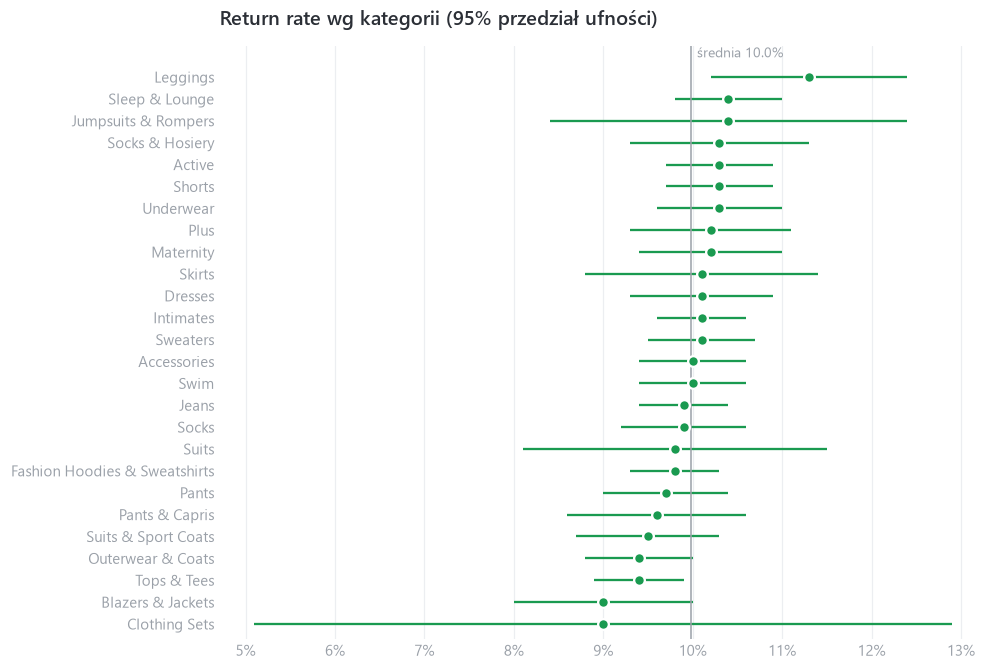

In [12]:
# Chart: return rate by category with 95% confidence intervals

overall_return = items_x["is_returned"].mean() * 100
plot_data = by_category.sort_values("return_rate")

fig, ax = plt.subplots(figsize=(9, 7))
ax.errorbar(plot_data["return_rate"], plot_data.index.astype(str), xerr=plot_data["return_ci"],
            fmt="o", color=COLORS["series_1"], ecolor=COLORS["series_1"], elinewidth=1.5, capsize=0,
            markersize=7, markeredgecolor=COLORS["surface"], markeredgewidth=1.5)

ax.axvline(overall_return, color=COLORS["muted"], linewidth=1)
ax.set_ylim(-0.7, len(plot_data) + 0.4)                     # room above the top category for the label
ax.annotate(f"średnia {overall_return:.1f}%", xy=(overall_return, len(plot_data) - 0.1),
            xytext=(4, 0), textcoords="offset points", color=COLORS["muted"], fontsize=9)

ax.set_title("Return rate wg kategorii (95% przedział ufności)")
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
ax.spines["bottom"].set_visible(False)
plt.show()

In [13]:
# Department (item level)

rate_table(items_x, "department")

,n,cancel_rate,return_rate,lost_value,cancel_z,return_z,return_ci
department,,,,,,,
Men,90568,14.9,10.0,1407833.0,-0.64,-0.17,0.2
Women,90178,15.1,10.0,1262694.0,0.64,0.17,0.2


In [14]:
# Top 20 brands by number of items sold – small brands would give noisy rates

top_brands = items_x["brand"].value_counts().head(20).index
rate_table(items_x[items_x["brand"].isin(top_brands)], "brand").sort_values("return_rate", ascending=False)

,n,cancel_rate,return_rate,lost_value,cancel_z,return_z,return_ci
brand,,,,,,,
Dickies,1169,15.7,11.9,12835.0,0.56,2.36,1.9
Nautica,1764,15.4,11.0,19216.0,0.32,1.65,1.5
Columbia,1512,15.9,10.6,27886.0,0.78,1.07,1.6
Diesel,1449,16.6,10.5,49805.0,1.57,0.84,1.6
Tommy Hilfiger,1583,15.1,10.4,31100.0,-0.06,0.71,1.5
Volcom,1867,16.1,10.2,29571.0,1.17,0.58,1.4
Quiksilver,1724,13.3,10.2,24589.0,-2.16,0.53,1.4
7 For All Mankind,1126,14.0,10.1,43010.0,-1.05,0.33,1.8
Hanes,1914,14.6,10.0,9296.0,-0.70,0.29,1.3


In [15]:
# Customer dimensions (order level): gender, top 10 countries, acquisition channel

top_countries = orders_x["country"].value_counts().head(10).index

display(rate_table(orders_x, "gender"))
display(rate_table(orders_x[orders_x["country"].isin(top_countries)], "country")
        .sort_values("return_rate", ascending=False))
rate_table(orders_x, "traffic_source").sort_values("return_rate", ascending=False)

,n,cancel_rate,return_rate,lost_value,cancel_z,return_z,return_ci
gender,,,,,,,
F,62182,15.1,10.0,1262694.0,0.73,0.1,0.2
M,62270,14.9,9.9,1407833.0,-0.73,-0.1,0.2


,n,cancel_rate,return_rate,lost_value,cancel_z,return_z,return_ci
country,,,,,,,
Japan,3137,13.5,10.7,65192.0,-2.34,1.51,1.1
Germany,5308,14.7,10.6,117446.0,-0.53,1.72,0.8
France,5806,15.1,10.5,127642.0,0.32,1.36,0.8
Spain,4936,15.2,10.3,103547.0,0.36,0.83,0.8
China,42131,14.9,9.9,904843.0,-0.52,-0.07,0.3
Brasil,18130,15.2,9.8,384124.0,0.68,-0.57,0.4
United States,28184,15.0,9.8,604311.0,0.29,-0.96,0.3
United Kingdom,5574,15.6,9.8,123515.0,1.33,-0.45,0.8
South Korea,6653,14.9,9.7,141352.0,-0.07,-0.70,0.7


,n,cancel_rate,return_rate,lost_value,cancel_z,return_z,return_ci
traffic_source,,,,,,,
Facebook,7472,15.7,10.0,164076.0,1.86,0.03,0.7
Search,87532,14.9,10.0,1876503.0,-0.27,0.41,0.2
Display,4938,15.3,9.9,108028.0,0.66,-0.18,0.8
Email,6194,15.0,9.9,136617.0,0.16,-0.08,0.7
Organic,18316,14.7,9.8,385303.0,-1.04,-0.77,0.4


## 3. Podsumowanie: sygnał czy szum?

Dla każdego wymiaru: ile grup ma |z| > 1,96 w zwrotach i anulowaniach, a ile **oczekiwalibyśmy przypadkiem** (5% grup).
Jeśli liczby są podobne – wymiar nie różnicuje strat.

In [16]:
# Signal vs noise across all dimensions

dimensions = {
    "category": rate_table(items_x, "category"),
    "department": rate_table(items_x, "department"),
    "brand (top 20)": rate_table(items_x[items_x["brand"].isin(top_brands)], "brand"),
    "gender": rate_table(orders_x, "gender"),
    "country (top 10)": rate_table(orders_x[orders_x["country"].isin(top_countries)], "country"),
    "traffic_source": rate_table(orders_x, "traffic_source"),
}

pd.DataFrame({
    name: {"groups": len(t),
           "expected_by_chance": round(0.05 * len(t), 1),
           "return_significant": int((t["return_z"].abs() > 1.96).sum()),
           "cancel_significant": int((t["cancel_z"].abs() > 1.96).sum()),
           "return_rate_min": t["return_rate"].min(),
           "return_rate_max": t["return_rate"].max(),
           "max_abs_z": t[["return_z", "cancel_z"]].abs().max().max()}
    for name, t in dimensions.items()
}).T

,groups,expected_by_chance,return_significant,cancel_significant,return_rate_min,return_rate_max,max_abs_z
category,26.0,1.3,2.0,4.0,9.0,11.3,2.76
department,2.0,0.1,0.0,0.0,10.0,10.0,0.64
brand (top 20),20.0,1.0,1.0,1.0,8.4,11.9,2.36
gender,2.0,0.1,0.0,0.0,9.9,10.0,0.73
country (top 10),10.0,0.5,0.0,1.0,9.6,10.7,2.34
traffic_source,5.0,0.2,0.0,0.0,9.8,10.0,1.86


## 4. Zysk po stratach

Łączymy z A3: ile zysku brutto (`sale_price - cost`) każda kategoria **zatrzymuje** (Complete + Shipped),
a ile **traci** (Cancelled + Returned)? Czy ranking kategorii po zysku zmienia się po uwzględnieniu strat?

In [17]:
# Gross profit kept vs lost by category

profit = (items_x
          .assign(gp_kept=lambda x: x["gross_profit"].where(x["status"].isin(REVENUE_STATUSES), 0),
                  gp_lost=lambda x: x["gross_profit"].where(x["status"].isin(LOST_STATUSES), 0))
          .groupby("category", observed=True)
          .agg(gp_kept=("gp_kept", "sum"), gp_lost=("gp_lost", "sum"))
          .assign(lost_share_pct=lambda x: x["gp_lost"] / (x["gp_kept"] + x["gp_lost"]) * 100,
                  rank_before=lambda x: (x["gp_kept"] + x["gp_lost"]).rank(ascending=False).astype(int),   # as if nothing were lost
                  rank_after=lambda x: x["gp_kept"].rank(ascending=False).astype(int))
          .sort_values("gp_kept", ascending=False)
          .round(1))

# Small swaps of neighbours are noise – look at the largest shift and rank correlation instead of "how many changed"
shift = (profit["rank_before"] - profit["rank_after"]).abs()
print(f"Największe przesunięcie w rankingu: {shift.max()} pozycji, średnie: {shift.mean():.1f}")
# Pearson correlation of ranks = Spearman correlation (no scipy needed)
print(f"Korelacja rankingów przed / po stratach (Spearman): {profit['rank_before'].corr(profit['rank_after']):.3f}")
profit

Największe przesunięcie w rankingu: 1 pozycji, średnie: 0.2
Korelacja rankingów przed / po stratach (Spearman): 0.999


,gp_kept,gp_lost,lost_share_pct,rank_before,rank_after
category,,,,,
Outerwear & Coats,402171.1,178811.8,30.8,1,1
Jeans,324795.7,144752.4,30.8,2,2
Sweaters,239255.0,109516.0,31.4,3,3
Suits & Sport Coats,216441.9,91220.9,29.6,4,4
Swim,172584.5,80174.1,31.7,5,5
Fashion Hoodies & Sweatshirts,171502.5,75255.1,30.5,6,6
Sleep & Lounge,157589.7,70606.4,30.9,7,7
Active,144351.9,72621.9,33.5,8,8
Accessories,143095.0,61618.1,30.1,10,9


## Wnioski (uzupełnij po uruchomieniu)

1.
2.
3.